# Лабораторная работа №4
## Линейная регрессия

Предсказание рождаемости в Москве по году. Данные: `russian_demography.csv`.
Модель: $\hat{y} = ax + b$, где $x$ — год, $\hat{y}$ — рождаемость.

При необходимости установите библиотеки в отдельной ячейке:
```python
%pip install numpy matplotlib scikit-learn
```

In [1]:
import csv

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

### 1. Данные

In [2]:
with open("russian_demography.csv", encoding="utf-8-sig", newline="") as file:
    data = [row for row in csv.DictReader(file) if row["region"] == "Moscow"]

X = np.array([int(row["year"]) for row in data]).reshape(-1, 1)
y = np.array([float(row["birth_rate"]) for row in data])

print(f"Москва: {X.min()}–{X.max()}, наблюдений: {len(y)}")

Москва: 1990–2017, наблюдений: 28


### 2. Построение прямой

In [3]:
model = LinearRegression()
model.fit(X, y)

print(f"Уравнение: y = {model.coef_[0]:.3f} * x {model.intercept_:+.3f}")


Уравнение: y = 0.163 * x -317.550


### 3. Визуализация

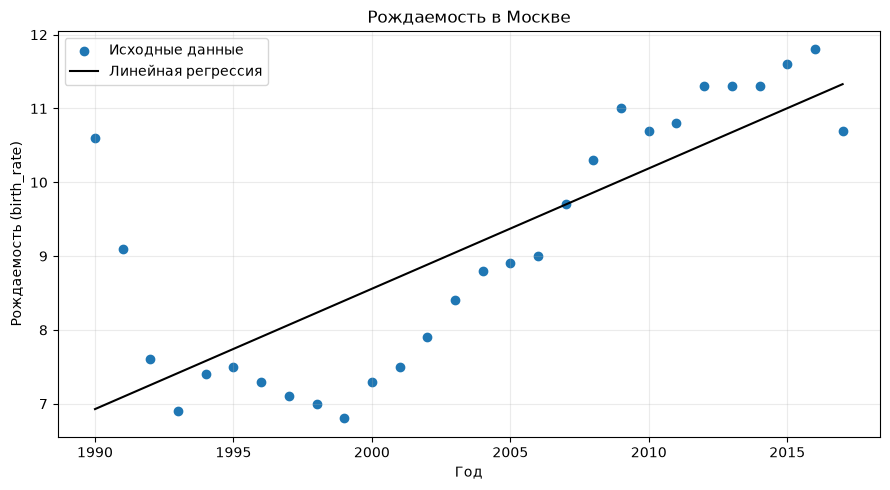

In [4]:
def plot_regression(year=None, birth_rate=None):
    left, right = X.min(), X.max()
    if year is not None:
        left, right = min(left, year), max(right, year)
    years = np.linspace(left, right, 200).reshape(-1, 1)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(X[:, 0], y, label="Исходные данные")
    ax.plot(years[:, 0], model.predict(years), color="black", label="Линейная регрессия")

    if year is not None:
        ax.scatter(
            year, birth_rate, color="crimson", marker="*", s=200,
            zorder=5, label=f"Прогноз на {year}: {birth_rate:.2f}"
        )

    ax.set_title("Рождаемость в Москве")
    ax.set_xlabel("Год")
    ax.set_ylabel("Рождаемость (birth_rate)")
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


plot_regression()

### 4. Предсказание по введённому году

Введите год: 2018
Год вне диапазона данных: экстраполяция.
Прогноз рождаемости на 2018 год: 11.49


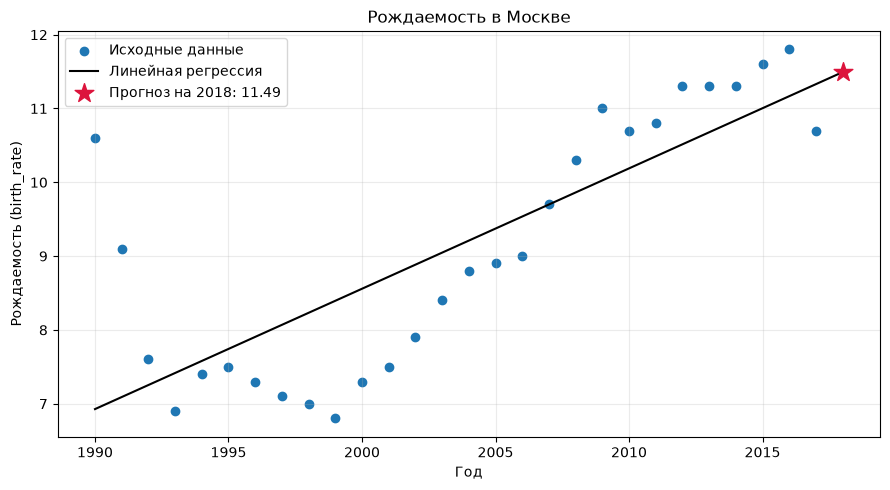

In [5]:
year = int(input("Введите год: "))
birth_rate = model.predict([[year]])[0]

if not X.min() <= year <= X.max():
    print("Год вне диапазона данных: экстраполяция.")

print(f"Прогноз рождаемости на {year} год: {birth_rate:.2f}")
plot_regression(year, birth_rate)